In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

import os
import zipfile
import urllib.request

url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/00331/"
    "sentiment%20labelled%20sentences.zip"
)

zip_path = "/content/sentiment_dataset.zip"
extract_path = "/content/sentiment_data"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset downloaded successfully!")


Dataset downloaded successfully!


In [3]:

import os
import pandas as pd

base_path = os.path.join(
    "/content/sentiment_data",
    "sentiment labelled sentences"
)

files = {
    "amazon": "amazon_cells_labelled.txt",
    "imdb": "imdb_labelled.txt",
    "yelp": "yelp_labelled.txt"
}

dataframes = []

for source, filename in files.items():
    file_path = os.path.join(base_path, filename)

    temp_df = pd.read_csv(
        file_path,
        sep="\t",
        header=None,
        names=["review", "sentiment"],
        encoding="utf-8"
    )

    temp_df["source"] = source
    dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset loaded successfully!")
print("Total reviews:", len(df))
display(df.head())


Dataset loaded successfully!
Total reviews: 2748


,review,sentiment,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


In [4]:

print("Total reviews:", len(df))

print("\nReviews by source:")
print(df["source"].value_counts())

print("\nSentiment labels:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 reviews:")
display(df.head())


Total reviews: 2748

Reviews by source:
source
amazon    1000
yelp      1000
imdb       748
Name: count, dtype: int64

Sentiment labels:
sentiment
1    1386
0    1362
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
source       0
dtype: int64

First 5 reviews:


,review,sentiment,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


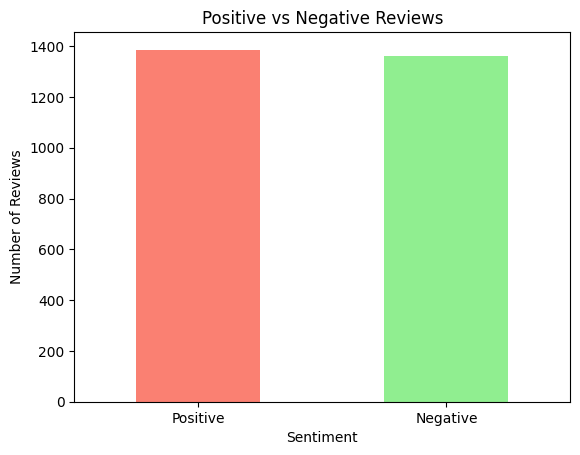

In [5]:

import matplotlib.pyplot as plt

sentiment_counts = df["sentiment"].map({
    0: "Negative",
    1: "Positive"
}).value_counts()

sentiment_counts.plot(
    kind="bar",
    color=["salmon", "lightgreen"],
    rot=0
)

plt.title("Positive vs Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


In [6]:

from sklearn.model_selection import train_test_split

# Input reviews
X = df["review"]

# Correct sentiment labels
y = df["sentiment"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("Data splitting completed successfully!")


Training reviews: 2198
Testing reviews: 550
Data splitting completed successfully!


In [7]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create the ML pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=10000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [8]:

from sklearn.metrics import accuracy_score, classification_report

# Predict sentiment for test reviews
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))


Model Accuracy: 81.64%

Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.86      0.82       273
    Positive       0.85      0.77      0.81       277

    accuracy                           0.82       550
   macro avg       0.82      0.82      0.82       550
weighted avg       0.82      0.82      0.82       550



In [9]:

def predict_sentiment(review):
    prediction = model.predict([review])[0]
    probabilities = model.predict_proba([review])[0]

    if prediction == 1:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    confidence = max(probabilities) * 100

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print(f"Model Confidence: {confidence:.2f}%")

# Test example
predict_sentiment(
    "The product is amazing and very useful"
)


Review: The product is amazing and very useful
Predicted Sentiment: Positive
Model Confidence: 77.83%


In [10]:

predict_sentiment("The product is very bad and disappointing")

predict_sentiment("I really love this product")

predict_sentiment("The quality is okay, nothing special")


Review: The product is very bad and disappointing
Predicted Sentiment: Negative
Model Confidence: 70.58%
Review: I really love this product
Predicted Sentiment: Positive
Model Confidence: 72.83%
Review: The quality is okay, nothing special
Predicted Sentiment: Negative
Model Confidence: 59.90%


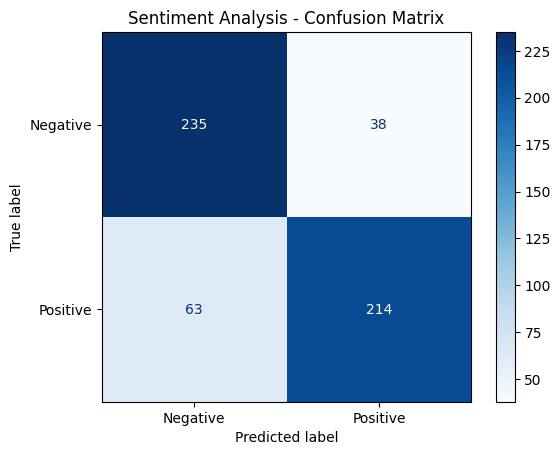

In [11]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Sentiment Analysis - Confusion Matrix")
plt.show()


# Machine Learning Based Sentiment Analysis of Customer Reviews

## 1. Objective
To classify customer reviews as Positive or Negative using Machine Learning and Natural Language Processing techniques.

## 2. Dataset
UCI Sentiment Labelled Sentences dataset. The current notebook contains 2,748 reviews from Amazon, Yelp, and IMDb.

## 3. Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- TF-IDF Vectorization
- Logistic Regression
- Matplotlib
- Google Colab

## 4. Methodology
1. Loaded and explored the review dataset.
2. Analysed positive and negative sentiment distribution.
3. Split the data into 80% training and 20% testing sets.
4. Converted text into numerical features using TF-IDF.
5. Trained a Logistic Regression classifier.
6. Evaluated the model using accuracy, precision, recall, F1-score, and a confusion matrix.
7. Tested the model using custom customer reviews.

## 5. Results
- Total reviews: 2,748
- Training reviews: 2,198
- Testing reviews: 550
- Test accuracy: 81.64%
- Correct predictions: 449
- Incorrect predictions: 101

## 6. Limitations
The model supports only Positive and Negative classes. It may misclassify neutral reviews, sarcasm, and complex sentences. The dataset is relatively small and may not represent all types of customer feedback.

## 7. Future Enhancements
- Add a Neutral sentiment class.
- Experiment with other classification algorithms.
- Improve performance with more diverse training data.
- Build a user-friendly interface for entering reviews.

## 8. Conclusion
This project demonstrates how Natural Language Processing and Machine Learning can be used to classify customer reviews. The baseline Logistic Regression model achieved 81.64% accuracy on the test set.